In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from Bio import SeqIO
import json
from io import StringIO
import requests
import time


In [4]:
# Load the BV-BRC antimicrobial resistance dataset.

df = pd.read_csv('../data/BVBRC_genome_amr.csv', low_memory=False)
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df['Antibiotic'].value_counts())

(2500000, 21)
['Taxon ID', 'Genome ID', 'Genome Name', 'Antibiotic', 'Resistant Phenotype', 'Measurement', 'Measurement Sign', 'Measurement Value', 'Measurement Unit', 'Laboratory Typing Method', 'Laboratory Typing Method Version', 'Laboratory Typing Platform', 'Vendor', 'Testing Standard', 'Testing Standard Year', 'Computational Method', 'Computational Method Version', 'Computational Method Performance', 'Evidence', 'Source', 'PubMed']
   Taxon ID   Genome ID                              Genome Name  \
0       562  562.174730         Escherichia coli strain UMDUCS23   
1       562  562.144628                      Escherichia coli 10   
2       562  562.529500                Escherichia coli upec-113   
3       562  562.178148            Escherichia coli PNUSAE022600   
4       562  562.226510  Escherichia coli O23:H16 strain ECO0238   

                      Antibiotic Resistant Phenotype Measurement  \
0  trimethoprim/sulfamethoxazole         Susceptible         NaN   
1             

In [4]:
# Inspect antibiotics
df['Antibiotic'].value_counts()

Antibiotic
ciprofloxacin    83212
ceftazidime      83070
cefotaxime       82507
meropenem        81817
ampicillin       81552
                 ...  
teicoplanin          1
sulbactam            1
daptomycin           1
linezolid            1
vancomycin           1
Name: count, Length: 106, dtype: int64

In [5]:
# Ciprofloxacin

ANTIBIOTIC = "ciprofloxacin"

df_drug = df[df['Antibiotic'].str.lower() == ANTIBIOTIC.lower()].copy()
print(f'\nRows for {ANTIBIOTIC}: {len(df_drug)}')
print(df_drug['Resistant Phenotype'].value_counts())



Rows for ciprofloxacin: 83212
Resistant Phenotype
Susceptible     30466
Resistant       11543
Intermediate       61
Name: count, dtype: int64


In [6]:
# Inspect Phenotype Values

print('Unique phenotype values:', df_drug['Resistant Phenotype'].unique())
df_drug['Resistant Phenotype'] = df_drug['Resistant Phenotype'].str.strip().str.capitalize()
print('After normalization:', df_drug['Resistant Phenotype'].unique())

Unique phenotype values: <StringArray>
['Resistant', nan, 'Susceptible', 'Intermediate']
Length: 4, dtype: str
After normalization: <StringArray>
['Resistant', nan, 'Susceptible', 'Intermediate']
Length: 4, dtype: str


In [7]:
df_drug.head()

,Taxon ID,Genome ID,Genome Name,Antibiotic,Resistant Phenotype,Measurement,Measurement Sign,Measurement Value,Measurement Unit,Laboratory Typing Method,...,Laboratory Typing Platform,Vendor,Testing Standard,Testing Standard Year,Computational Method,Computational Method Version,Computational Method Performance,Evidence,Source,PubMed
13,562,562.193047,Escherichia coli ECBSAC210134367,ciprofloxacin,Resistant,NaN,NaN,NaN,NaN,NaN,...,NaN,BVBRC,NaN,NaN,SIR XGBoost Model,20250225.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN
103,562,562.668750,Escherichia coli strain JS316,ciprofloxacin,NaN,8.0,NaN,8.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN
144,562,562.362490,Escherichia coli strain CP53,ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN
150,562,562.102588,Escherichia coli LN144,ciprofloxacin,NaN,1.0,NaN,1.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN
172,562,562.213610,Escherichia coli strain MOD1-EC6616,ciprofloxacin,NaN,4.0,NaN,4.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN


In [7]:
# Drop missing phenotype

df_drug = df_drug.dropna(subset='Resistant Phenotype')

print(df_drug['Resistant Phenotype'].unique())

<StringArray>
['Resistant', 'Susceptible', 'Intermediate']
Length: 3, dtype: str


In [8]:
# Drop Intermediate

df_clean = df_drug[df_drug['Resistant Phenotype'].isin(['Resistant', 'Susceptible'])].copy()

In [9]:
# Convert to binary int

df_clean['label'] =(df_clean['Resistant Phenotype'] == 'Resistant').astype(int)

print('\nLabel Distribution:')
print(df_clean['label'].value_counts())
print(f'Class balance: {df_clean['label'].mean():.1%} resistant')


Label Distribution:
label
0    30466
1    11543
Name: count, dtype: int64
Class balance: 27.5% resistant


Class balance looks reasonable: 27.5% minority class.


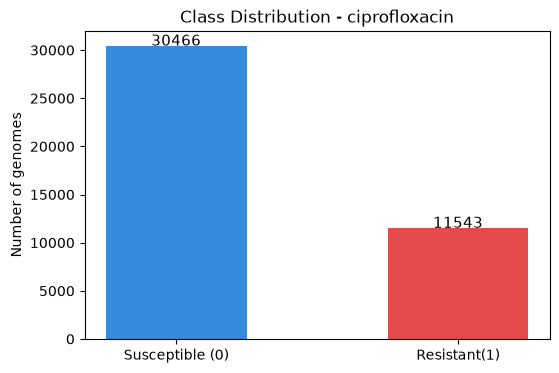

In [46]:
# Visualize class distribution and check for imbalance.

counts = df_clean['label'].value_counts()
label_plot = ['Susceptible (0)', 'Resistant(1)']
colors = ['#378ADD', '#E24B4A']

plt.figure(figsize=(6,4))
bars = plt.bar(label_plot, [counts.get(0,0), counts.get(1,0)], color = colors, width=0.5)
plt.title(f"Class Distribution - {ANTIBIOTIC}")
plt.ylabel('Number of genomes')

for bar, count in zip(bars, [counts.get(0,0), counts.get(1,0)]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+2, str(count), ha = 'center', fontsize=11)

minority_pct = min(counts) / sum(counts)
if minority_pct < 0.20:
    print(f"WARNING: minority class is only {minority_pct:.1%} of data.")
    print("Consider using class_weight='balanced' in your model (Stage 6).")
else:
    print(f"Class balance looks reasonable: {minority_pct:.1%} minority class.")

plt.savefig('../plots/class_distribution_ciproflaxin.png', dpi=500, bbox_inches="tight")



In [91]:
genome_dir = "../bvbrc_fna/"   

genomes = {}
for fname in os.listdir(genome_dir):
    if not fname.endswith((".fna", ".fasta")):
        continue
    gid = fname.replace(".fna", "").replace(".fasta", "").strip()
    records = list(SeqIO.parse(os.path.join(genome_dir, fname), "fasta"))
    if records:
        genomes[gid] = "".join(str(r.seq).upper() for r in records)

print(f"Loaded {len(genomes)} genomes")
for gid, seq in list(genomes.items())[:3]:
    print(f"  {gid}: {len(seq):,} bp")

Loaded 929 genomes
  562.94289: 5,855,691 bp
  562.175696: 723,624 bp
  562.99534: 1,019,526 bp


In [93]:
if not genomes:
    raise RuntimeError("No genomes loaded — check the genome_folder path")

lengths = [len(s) for s in genomes.values()]
print(f"\nGenome length: min={min(lengths):,}  max={max(lengths):,}  "
      f"mean={np.mean(lengths):,.0f}  median={np.median(lengths):,.0f}")

SHORT_THRESHOLD = 1_000_000
short = {g: len(s) for g, s in genomes.items() if len(s) < SHORT_THRESHOLD}
if short:
    print(f"\n  {len(short)} genomes under {SHORT_THRESHOLD:,} bp:")
    for g, n in short.items():
        print(f"  {g}: {n:,} bp")
    # Drop them
    genomes = {g: s for g, s in genomes.items() if len(s) >= SHORT_THRESHOLD}

print("\nN content (first 5):")
for gid, seq in list(genomes.items())[:5]:
    n_pct = (seq.count("N") / len(seq)) * 100
    print(f"  {gid}: {n_pct:.2f}% N")


Genome length: min=5,631  max=5,855,691  mean=1,440,459  median=995,434

  466 genomes under 1,000,000 bp:
  562.175696: 723,624 bp
  562.172327: 394,929 bp
  562.121999: 970,371 bp
  562.55007: 335,683 bp
  562.65533: 607,108 bp
  562.175058: 918,318 bp
  562.23301: 847,158 bp
  562.48054: 686,462 bp
  562.174529: 448,181 bp
  1055537.35: 878,973 bp
  562.52647: 57,407 bp
  562.7322: 236,677 bp
  562.80361: 279,588 bp
  562.134286: 873,456 bp
  562.144587: 442,794 bp
  562.114787: 364,223 bp
  562.56766: 555,552 bp
  562.187406: 588,165 bp
  562.144623: 292,649 bp
  562.141784: 219,459 bp
  562.55094: 130,816 bp
  562.88065: 213,212 bp
  562.30612: 504,456 bp
  562.90744: 681,912 bp
  562.17309: 838,732 bp
  562.59225: 746,812 bp
  562.57477: 889,152 bp
  562.101977: 484,744 bp
  562.134181: 845,758 bp
  562.46808: 883,136 bp
  562.2284: 453,059 bp
  562.70696: 684,677 bp
  562.126141: 620,199 bp
  562.50224: 551,083 bp
  562.9751: 555,137 bp
  562.70452: 403,198 bp
  562.139336: 413

In [94]:
len(genomes)

463

In [95]:
if not genomes:
    print("Error: The 'genomes' dictionary is empty. Please check your data loading step.")
else:
    lengths = [len(seq) for seq in genomes.values()]

    print("Genome length stat")
    print(f"  Min:    {min(lengths):>12,} bp")
    print(f"  Max:    {max(lengths):>12,} bp")
    print(f"  Mean:   {np.mean(lengths):>12,.0f} bp")
    print(f"  Median: {np.median(lengths):>12,.0f} bp")

# Flag suspiciously short genomes (likely corrupt or wrong organism)
    SHORT_THRESHOLD = 1_000_000  # 1 million bp
    short_genomes = {gid: len(seq) for gid, seq in genomes.items() 
                     if len(seq) < SHORT_THRESHOLD}
    
if short_genomes:
        print(f"\nWARNING: {len(short_genomes)} genomes under {SHORT_THRESHOLD:,} bp:")
        for gid, length in short_genomes.items():
            print(f"  {gid}: {length:,} bp  ← consider removing")
else:
     print(f"\nAll genomes above {SHORT_THRESHOLD:,} bp — looking good.")

# Check N content (ambiguous bases)
print("\nAmbiguous base (N) content")
for genome_id, seq in list(genomes.items())[:5]:  # check first 5
    n_count = seq.count('N')
    n_pct = (n_count / len(seq)) * 100
    print(f"  {genome_id}: {n_pct:.2f}% N bases")

Genome length stat
  Min:       1,006,988 bp
  Max:       5,855,691 bp
  Mean:      2,295,721 bp
  Median:    1,584,742 bp

All genomes above 1,000,000 bp — looking good.

Ambiguous base (N) content
  562.94289: 0.00% N bases
  562.99534: 0.00% N bases
  562.136296: 0.00% N bases
  562.144777: 0.00% N bases
  562.88468: 0.00% N bases


In [96]:
label_lookup = df_clean.set_index("Genome ID")["label"].to_dict()
usable_ids = sorted([g for g in genomes if g in label_lookup])

no_label = sorted([g for g in genomes if g not in label_lookup])

print(f"MATCH RESULT")
print(f"Genomes on disk:     {len(genomes)}")
print(f"Genomes with label:  {len(usable_ids)}")
print(f"Genomes without lbl: {len(no_label)}")
if no_label:
    print(f"  Examples: {no_label[:5]}")

y = np.array([label_lookup[g] for g in usable_ids], dtype=np.int32)
print(f"\nClass balance: {dict(zip(*np.unique(y, return_counts=True)))}")
print(f"Resistant rate: {y.mean():.1%}")

MATCH RESULT
Genomes on disk:     463
Genomes with label:  463
Genomes without lbl: 0

Class balance: {np.int32(0): np.int64(339), np.int32(1): np.int64(124)}
Resistant rate: 26.8%


In [ ]:
os.makedirs("../features", exist_ok=True)

# Save the genome_order so row i ↔ genome_id is traceable
with open("../features/genome_order.txt", "w") as f:
    for gid in usable_ids:
        f.write(gid + "\n")

# Save genomes dict (optional, large)
with open("../features/genomes.json", "w") as f:
    json.dump({g: genomes[g] for g in usable_ids}, f)

print(f"\nSaved genome_order.txt ({len(usable_ids)} genomes)")
print(f"Ready to featurize — X will be ({len(usable_ids)}, 256), y = {y.shape}")


Saved genome_order.txt (463 genomes)
Ready to featurize — X will be (463, 256), y = (463,)


In [10]:
df_clean.to_csv('../data/cleaned.csv', index=False)

In [11]:
df_clean.head()

,Taxon ID,Genome ID,Genome Name,Antibiotic,Resistant Phenotype,Measurement,Measurement Sign,Measurement Value,Measurement Unit,Laboratory Typing Method,...,Vendor,Testing Standard,Testing Standard Year,Computational Method,Computational Method Version,Computational Method Performance,Evidence,Source,PubMed,label
13,562,562.193047,Escherichia coli ECBSAC210134367,ciprofloxacin,Resistant,NaN,NaN,NaN,NaN,NaN,...,BVBRC,NaN,NaN,SIR XGBoost Model,20250225.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN,1
144,562,562.362490,Escherichia coli strain CP53,ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN,0
192,562,562.969410,Escherichia coli VRES1191,ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN,0
329,562,562.142721,Escherichia coli JBCCABB-19-0045,ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN,0
333,562,562.228540,Escherichia coli NA:H6 strain ECO0471,ciprofloxacin,Resistant,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN,1
